# Performance diagrams from the tile output

The 2×2 tables come from the `tiles_*.csv` files written by `do_verf_outlooks_tiles.ipynb` and `do_verf_pph_tiles.ipynb`. A threshold p makes "yes" everywhere the forecast is at or above p. a, b, c and d are then sums of `area_km2` and `obs_*` over the pieces, divided by the total area. The background, no-skill and unachievable regions, and bias contours follow `intro_performance_diagram.ipynb`.

- **Figure 1:** the coverage probabilities as forecasts of any report. Each probability level is a threshold, so each product traces a curve.
- **Figure 2:** CIG ≥ k as a yes/no forecast of a significant report. The sample here is only the area within 40 km of any report, so `area_km2` is replaced by the `obs` column at the lowest threshold.

In [1]:
import os, numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt, matplotlib.patches as patches
from scipy.stats import norm
H = os.path.expanduser
# output folders of do_verf_outlooks_tiles.ipynb and do_verf_pph_tiles.ipynb
SRC = {'SPC 1630 outlook': H('~/datasets/outlook_tiles_2026'), 'PPH 1630': H('~/datasets/pph_tiles_2026')}
FIG_DIR = H('~/datasets/outlook_tiles_2026')
STYLE = {'SPC 1630 outlook': dict(color='#1f4e9c', marker='o'), 'PPH 1630': dict(color='#e6550d', marker='s')}
HAZ = {'torn': ('Tornado', 'obs_ef0', 'obs_ef2', 'EF2+'), 'wind': ('Wind', 'obs_50kt', 'obs_65kt', '65 kt+'),
       'hail': ('Hail', 'obs_1p0in', 'obs_2p0in', '2 in+')}

# --- score functions (from intro_performance_diagram.ipynb) ---
def csi(a,b,c,d): return a/(a+b+c)
def hss(a,b,c,d): return 2.*(a*d-b*c)/((a+c)*(c+d)+(a+b)*(b+d))
def dprime(a,b,c,d): return norm.ppf(a/(a+c))-norm.ppf(b/(b+d))
def bias(a,b,c,d): return (a+b)/(a+c)
BACKGROUNDS = {'CSI': (csi, np.linspace(0, 1, 21), np.linspace(0, 1, 11), 'neither'),
               'HSS': (hss, np.linspace(0, 1, 21), np.linspace(0, 1, 11), 'neither'),
               "d'":  (dprime, np.linspace(0, 4, 17), np.linspace(0, 4, 9), 'max')}

def table_2x2(t, fcol, area_col, obs_col):
    # one row per threshold: forecast "yes" where fcol >= threshold; elements as fractions of the total area
    g = t.groupby(fcol)[[area_col, obs_col]].sum()
    A, O = g[area_col].values, g[obs_col].values; N = A.sum()
    rows = []
    for k, thr in enumerate(g.index):
        if k == 0: continue
        yes = g.index >= thr
        a = O[yes].sum() / N; b = (A - O)[yes].sum() / N
        c = O.sum() / N - a; d = 1 - a - b - c
        rows.append(dict(thresh=thr, a=a, b=b, c=c, d=d, POD=a / (a + c), SR=a / (a + b) if a + b > 0 else np.nan))
    return pd.DataFrame(rows), O.sum() / N

def background(ax, xbar, name):
    fn, lvls, ticks, ext = BACKGROUNDS[name]
    pod_y = np.arange(0.001, 1.0, 0.001); sr_x = np.arange(0.001, 1.0, 0.001)
    sr_perf, pod_perf = np.meshgrid(sr_x, pod_y)
    aa = xbar * pod_perf; bb = xbar * (pod_perf / sr_perf - pod_perf); cc = xbar * (1. - pod_perf); dd = 1. - xbar * (pod_perf / sr_perf + 1. - pod_perf)
    for arr in (aa, bb, cc, dd): arr[sr_perf < xbar] = np.nan
    with np.errstate(all='ignore'):
        cs0 = ax.contour(sr_x, pod_y, bias(aa, bb, cc, dd), levels=[0.1, 0.25, 0.5, 0.75, 1., 1.33, 2., 4., 10.], colors='k', linestyles='dashed', linewidths=0.7)
        ax.clabel(cs0, cs0.levels, inline=True, fontsize=7)
        sc = ax.contourf(sr_x, pod_y, fn(aa, bb, cc, dd), levels=lvls, cmap='RdGy_r', extend=ext)
    plt.colorbar(sc, ax=ax, shrink=0.78, ticks=ticks, label=name)
    ax.plot([xbar, xbar], [0, 1], 'k--', lw=0.8)
    sr_min = xbar * pod_y / (1. - xbar + xbar * pod_y)
    ax.add_patch(patches.Polygon(np.array([np.append(sr_min, [0., 0.]), np.append(pod_y, [1., 0.])]).T, hatch='xx', lw=0, fill=None, zorder=1))
    ax.add_patch(patches.Polygon(np.array([np.append(sr_min, [xbar, 0.]), np.append(pod_y, [0., 0.])]).T, hatch='..', lw=0, fill=None, zorder=-5))
    ax.set_aspect('equal'); ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_xlabel('SR'); ax.set_ylabel('POD')

def curves(ax, tabs, label_fmt):
    for s, df in tabs.items():
        st = STYLE[s]
        ax.plot(df.SR, df.POD, '-', color=st['color'], lw=1.8, marker=st['marker'], ms=5, mec='k', mew=0.5, label=s, zorder=6)
        for r in df.itertuples():
            if np.isfinite(r.SR) and r.POD > 0.02:
                ax.annotate(label_fmt(r.thresh), (r.SR, r.POD), xytext=(4, 3), textcoords='offset points', fontsize=7, color=st['color'], zorder=7)

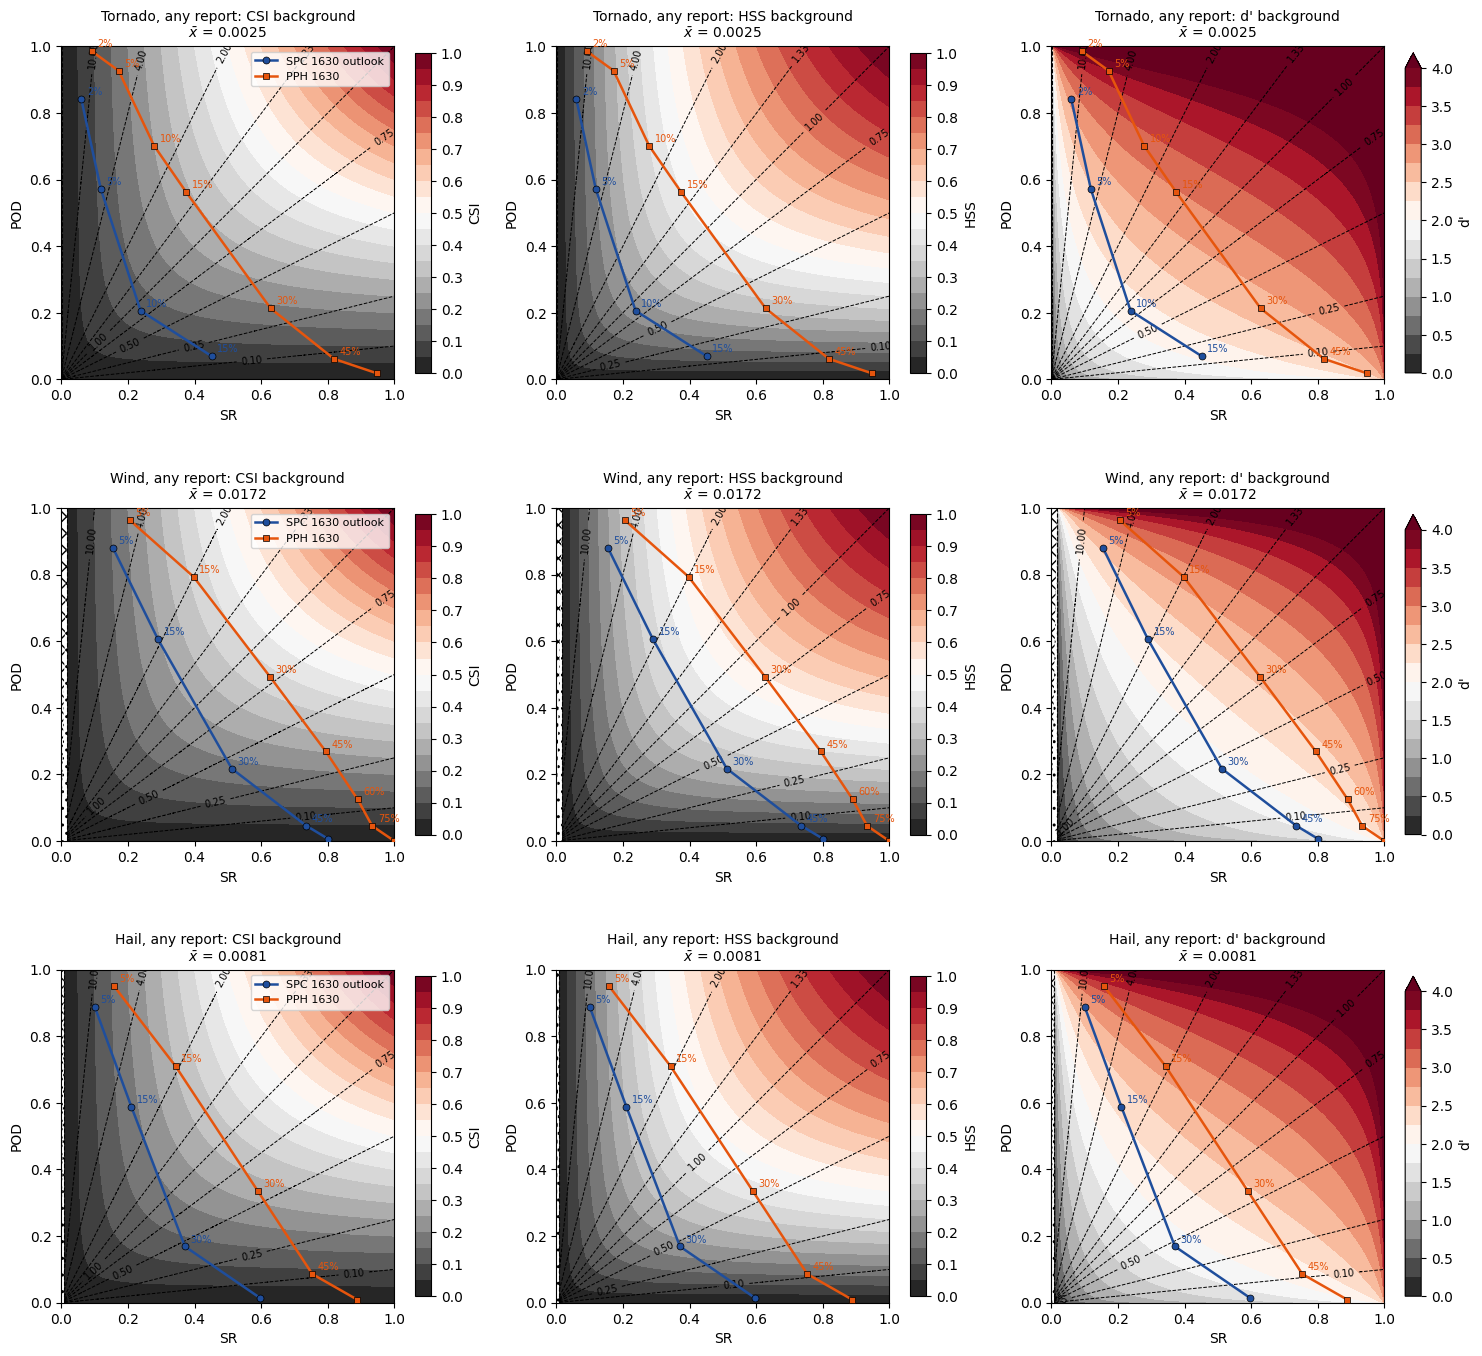

base rates (SPC, PPH): [('torn', np.float64(0.00254)), ('wind', np.float64(0.01723)), ('hail', np.float64(0.00811))]
          source hazard  thresh   POD    SR   bias   CSI   HSS    d'
SPC 1630 outlook   torn     2.0 0.842 0.060 14.030 0.059 0.108 2.833
SPC 1630 outlook   torn     5.0 0.572 0.119  4.820 0.109 0.193 2.478
SPC 1630 outlook   torn    10.0 0.206 0.238  0.867 0.124 0.219 2.113
SPC 1630 outlook   torn    15.0 0.070 0.451  0.155 0.065 0.121 2.043
        PPH 1630   torn     2.0 0.985 0.092 10.712 0.092 0.164 4.132
        PPH 1630   torn     5.0 0.927 0.172  5.392 0.170 0.287 3.732
        PPH 1630   torn    10.0 0.701 0.279  2.516 0.249 0.397 3.131
        PPH 1630   torn    15.0 0.563 0.374  1.504 0.290 0.448 2.980
        PPH 1630   torn    30.0 0.213 0.628  0.339 0.189 0.318 2.618
        PPH 1630   torn    45.0 0.062 0.819  0.075 0.061 0.114 2.437
        PPH 1630   torn    60.0 0.018 0.948  0.019 0.018 0.036 2.468
SPC 1630 outlook   wind     5.0 0.881 0.155  5.698 0.15

In [2]:
# ---- figure 1: coverage probabilities vs any report ----
fig, axes = plt.subplots(3, 3, figsize=(15, 14))
out1 = []
for i, (h, (title, any_col, sig_col, sig_lab)) in enumerate(HAZ.items()):
    tabs, xb = {}, {}
    for s, d in SRC.items():
        t = pd.read_csv(f'{d}/tiles_{h}.csv')
        tabs[s], xb[s] = table_2x2(t, 'prob', 'area_km2', any_col)
        out1.append(tabs[s].assign(source=s, hazard=h))
    xbar = xb['SPC 1630 outlook']
    for j, name in enumerate(BACKGROUNDS):
        ax = axes[i, j]; background(ax, xbar, name)
        curves(ax, tabs, lambda v: f'{v:g}%')
        ax.set_title(f'{title}, any report: {name} background\n' + r'$\bar x$' + f' = {xbar:.4f}', fontsize=10)
        if j == 0: ax.legend(loc='upper right', fontsize=8)
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/perf_coverage_1630.png', dpi=130); plt.show()
print('base rates (SPC, PPH):', [(h, round(x, 5)) for h in HAZ for x in [table_2x2(pd.read_csv(f"{SRC['SPC 1630 outlook']}/tiles_{h}.csv"), 'prob', 'area_km2', HAZ[h][1])[1]]])
o1 = pd.concat(out1); o1['HSS'] = hss(o1.a, o1.b, o1.c, o1.d); o1['CSI'] = csi(o1.a, o1.b, o1.c, o1.d); o1['bias'] = bias(o1.a, o1.b, o1.c, o1.d)
with np.errstate(all='ignore'): o1["d'"] = dprime(o1.a, o1.b, o1.c, o1.d)
print(o1[['source', 'hazard', 'thresh', 'POD', 'SR', 'bias', 'CSI', 'HSS', "d'"]].round(3).to_string(index=False))

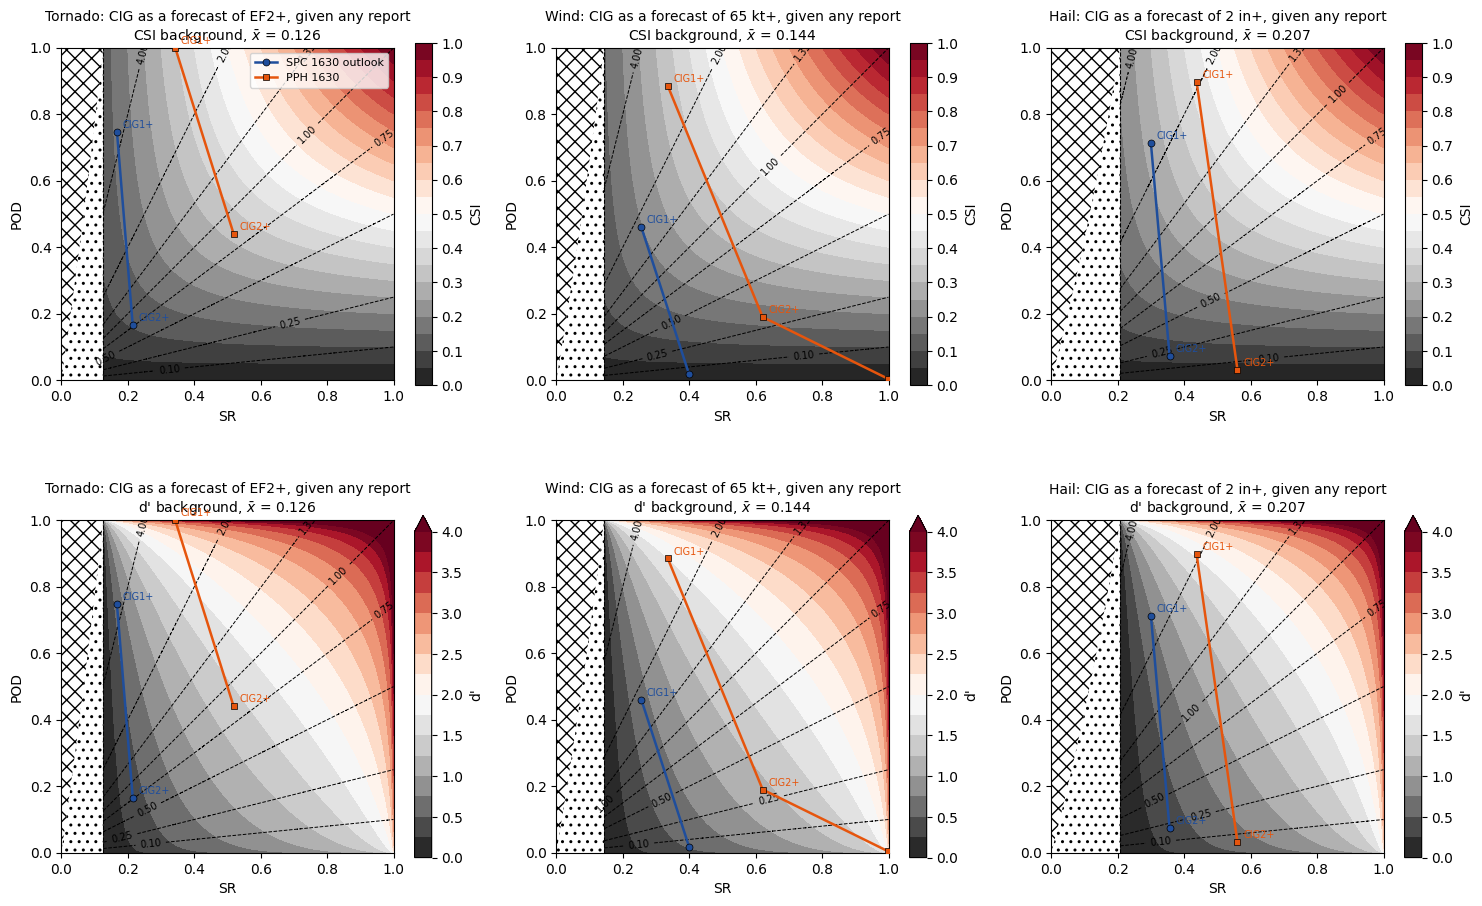

          source hazard  base_rate  thresh   POD    SR  bias   CSI   HSS    d'
SPC 1630 outlook   torn      0.126       1 0.748 0.167 4.466 0.158 0.085 0.577
SPC 1630 outlook   torn      0.126       2 0.165 0.215 0.769 0.103 0.087 0.387
        PPH 1630   torn      0.126       1 1.000 0.343 2.918 0.343 0.397   inf
        PPH 1630   torn      0.126       2 0.441 0.518 0.851 0.313 0.408 1.414
SPC 1630 outlook   wind      0.144       1 0.460 0.256 1.797 0.197 0.177 0.657
SPC 1630 outlook   wind      0.144       2 0.019 0.399 0.047 0.018 0.023 0.514
        PPH 1630   wind      0.144       1 0.885 0.335 2.638 0.321 0.351 1.741
        PPH 1630   wind      0.144       2 0.190 0.621 0.306 0.170 0.240 1.187
        PPH 1630   wind      0.144       3 0.004 0.999 0.004 0.004 0.007 2.117
SPC 1630 outlook   hail      0.207       1 0.713 0.300 2.378 0.267 0.184 0.726
SPC 1630 outlook   hail      0.207       2 0.074 0.356 0.209 0.065 0.055 0.366
        PPH 1630   hail      0.207       1 0.897 0.4

In [3]:
# ---- figure 2: CIG >= k as a yes/no forecast of a significant report, given any report ----
fig, axes = plt.subplots(2, 3, figsize=(15, 9.6))
out2 = []
for j, (h, (title, any_col, sig_col, sig_lab)) in enumerate(HAZ.items()):
    tabs, xb = {}, {}
    for s, d in SRC.items():
        t = pd.read_csv(f'{d}/tiles_{h}.csv')
        tabs[s], xb[s] = table_2x2(t, 'cig', any_col, sig_col)
        out2.append(tabs[s].assign(source=s, hazard=h, base_rate=xb[s]))
    xbar = xb['SPC 1630 outlook']
    for i, name in enumerate(['CSI', "d'"]):
        ax = axes[i, j]; background(ax, xbar, name)
        curves(ax, tabs, lambda v: f'CIG{v:g}+')
        ax.set_title(f'{title}: CIG as a forecast of {sig_lab}, given any report\n{name} background, ' + r'$\bar x$' + f' = {xbar:.3f}', fontsize=10)
        if i == 0 and j == 0: ax.legend(loc='upper right', fontsize=8)
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/perf_cig_1630.png', dpi=130); plt.show()
o2 = pd.concat(out2); o2['HSS'] = hss(o2.a, o2.b, o2.c, o2.d); o2['CSI'] = csi(o2.a, o2.b, o2.c, o2.d); o2['bias'] = bias(o2.a, o2.b, o2.c, o2.d)
with np.errstate(all='ignore'): o2["d'"] = dprime(o2.a, o2.b, o2.c, o2.d)
print(o2[['source', 'hazard', 'base_rate', 'thresh', 'POD', 'SR', 'bias', 'CSI', 'HSS', "d'"]].round(3).to_string(index=False))